In [ ]:
!pip -q install transformers accelerate xgboost lightgbm catboost

In [ ]:
import os, re, gc, zipfile, requests, warnings, random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", DEVICE)

DATA_DIR = Path("/content/data")
RESULT_DIR = Path("/content/results")

DATA_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

# Experiment settings
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 2

# Limit training data initially for Colab GPU execution.
# Change to None to use the complete training dataset.
MAX_TRAIN_ROWS = 10000

Running on: cpu


In [ ]:
# Download WELFake from Zenodo
wel_path = DATA_DIR / "WELFake_Dataset.csv"

if not wel_path.exists():
    url = (
        "https://zenodo.org/api/records/4561253/files/"
        "WELFake_Dataset.csv/content"
    )
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    wel_path.write_bytes(r.content)

print("WELFake downloaded:", wel_path)

# Download LIAR dataset
liar_zip = DATA_DIR / "liar_dataset.zip"

if not liar_zip.exists():
    url = "https://www.cs.ucsb.edu/~william/data/liar_dataset.zip"
    r = requests.get(url, timeout=180)
    r.raise_for_status()
    liar_zip.write_bytes(r.content)

liar_dir = DATA_DIR / "liar"
liar_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(liar_zip) as z:
    z.extractall(liar_dir)

print("LIAR downloaded successfully")

WELFake downloaded: /content/data/WELFake_Dataset.csv
LIAR downloaded successfully


In [ ]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# WELFake preprocessing
wel = pd.read_csv(wel_path)

wel.columns = [str(c).strip().lower() for c in wel.columns]

wel["content"] = (
    wel["title"].fillna("").astype(str)
    + " "
    + wel["text"].fillna("").astype(str)
)

wel["content"] = wel["content"].apply(clean_text)
wel["label"] = pd.to_numeric(wel["label"], errors="coerce")

wel = wel.dropna(subset=["label"])
wel["label"] = wel["label"].astype(int)
wel = wel[wel["label"].isin([0, 1])]
wel = wel[wel["content"].str.len() > 5]
wel = wel.drop_duplicates("content")

wel = wel[["content", "label"]].reset_index(drop=True)


# LIAR preprocessing
LIAR_COLUMNS = [
    "id", "label", "statement", "subject", "speaker",
    "job_title", "state_info", "party_affiliation",
    "barely_true_counts", "false_counts",
    "half_true_counts", "mostly_true_counts",
    "pants_on_fire_counts", "context"
]

def read_liar(filename):
    paths = list(liar_dir.rglob(filename))
    if not paths:
        raise FileNotFoundError(filename)
    return pd.read_csv(
        paths[0], sep="\t", header=None,
        names=LIAR_COLUMNS, quoting=3,
        on_bad_lines="skip", dtype=str
    )

liar_train = read_liar("train.tsv")
liar_valid = read_liar("valid.tsv")
liar_test = read_liar("test.tsv")

label_map = {
    "pants-fire": 0,
    "false": 0,
    "barely-true": 0,
    "half-true": 1,
    "mostly-true": 1,
    "true": 1
}

liar_train = pd.concat(
    [liar_train, liar_valid], ignore_index=True
)

def prepare_liar(df):
    df = df.copy()
    df["label"] = (
        df["label"].str.lower().str.strip().map(label_map)
    )
    df["content"] = df["statement"].apply(clean_text)
    df = df.dropna(subset=["label"])
    df["label"] = df["label"].astype(int)
    df = df[df["content"].str.len() > 2]
    return df[["content", "label"]].reset_index(drop=True)

liar_train = prepare_liar(liar_train)
liar_test = prepare_liar(liar_test)

print("WELFake:", wel.shape)
print("LIAR training:", liar_train.shape)
print("LIAR testing:", liar_test.shape)

WELFake: (63664, 2)
LIAR training: (11553, 2)
LIAR testing: (1283, 2)


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class FakeNewsDataset(Dataset):

    def __init__(self, texts, labels):
        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            {k: v[idx] for k, v in self.encodings.items()},
            self.labels[idx]
        )


class HybridBertLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.bert = AutoModel.from_pretrained(MODEL_NAME)

        hidden_size = self.bert.config.hidden_size

        self.lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=128,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.classifier = nn.Linear(
            hidden_size + 256, 2
        )

    def forward(self, input_ids, attention_mask, **kwargs):

        bert_output = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence = bert_output.last_hidden_state

        lstm_output, _ = self.lstm(sequence)

        mask = attention_mask.unsqueeze(-1).float()

        lstm_features = (
            (lstm_output * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        bert_features = sequence[:, 0, :]

        hybrid_features = torch.cat(
            [bert_features, lstm_features],
            dim=1
        )

        output = self.classifier(
            self.dropout(hybrid_features)
        )

        return (
            output,
            bert_features,
            lstm_features,
            hybrid_features
        )

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
def train_hybrid_model(x_train, y_train, x_test, y_test):

    train_ds = FakeNewsDataset(x_train, y_train)
    test_ds = FakeNewsDataset(x_test, y_test)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True
    )

    test_loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False
    )

    model = HybridBertLSTM().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=2e-5
    )

    loss_function = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):

        model.train()
        total_loss = 0

        for batch, labels in train_loader:

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs, *_ = model(**batch)

            loss = loss_function(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{EPOCHS}, "
            f"Loss: {total_loss/len(train_loader):.4f}"
        )

    def extract(loader):

        model.eval()

        bert_all = []
        lstm_all = []
        hybrid_all = []
        probabilities = []
        actual = []

        with torch.no_grad():

            for batch, labels in loader:

                batch = {
                    k: v.to(DEVICE)
                    for k, v in batch.items()
                }

                outputs, bert, lstm, hybrid = model(**batch)

                bert_all.append(bert.cpu().numpy())
                lstm_all.append(lstm.cpu().numpy())
                hybrid_all.append(hybrid.cpu().numpy())

                probabilities.extend(
                    torch.softmax(outputs, dim=1)[:, 1]
                    .cpu().numpy()
                )

                actual.extend(labels.numpy())

        return (
            np.vstack(bert_all),
            np.vstack(lstm_all),
            np.vstack(hybrid_all),
            np.array(probabilities),
            np.array(actual)
        )

    train_features = extract(
        DataLoader(train_ds, batch_size=BATCH_SIZE)
    )

    test_features = extract(test_loader)

    features = {
        "BERT": (
            train_features[0], test_features[0]
        ),
        "LSTM": (
            train_features[1], test_features[1]
        ),
        "HYBRID_LSTM_BERT": (
            train_features[2], test_features[2]
        )
    }

    return features, test_features[3]

In [ ]:
def calculate_metrics(y_true, y_pred, y_score=None):

    result = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true, y_pred, average="macro",
            zero_division=0
        )
    }

    try:
        result["ROC_AUC"] = (
            roc_auc_score(y_true, y_score)
            if y_score is not None else np.nan
        )
    except Exception:
        result["ROC_AUC"] = np.nan

    return result


def evaluate_model(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = None

    return calculate_metrics(
        y_test, predictions, scores
    )

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def run_stacking_experiment(
    dataset_name, feature_sets, y_train, y_test
):

    results = []

    for feature_name, (X_train, X_test) in feature_sets.items():

        print(
            f"\nStacking experiment: "
            f"{dataset_name} | {feature_name}"
        )

        individual_models = {
            "LogisticRegression": LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=SEED
            ),

            "SVM": LinearSVC(
                class_weight="balanced",
                random_state=SEED
            ),

            "RandomForest": RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced",
                n_jobs=-1,
                random_state=SEED
            )
        }

        # Individual models
        for model_name, model in individual_models.items():

            try:
                scores = evaluate_model(
                    model,
                    X_train,
                    y_train,
                    X_test,
                    y_test
                )

                results.append({
                    "Dataset": dataset_name,
                    "Features": feature_name,
                    "Model": model_name,
                    **scores
                })

                print(
                    model_name,
                    "Accuracy:",
                    round(scores["Accuracy"] * 100, 2)
                )

            except Exception as error:
                print(
                    "Individual model error:",
                    model_name,
                    error
                )

        # Stacking ensemble
        stacking_model = StackingClassifier(
            estimators=[
                (
                    "lr",
                    LogisticRegression(
                        max_iter=1000,
                        class_weight="balanced"
                    )
                ),
                (
                    "svm",
                    LinearSVC(
                        class_weight="balanced",
                        random_state=SEED
                    )
                ),
                (
                    "rf",
                    RandomForestClassifier(
                        n_estimators=100,
                        class_weight="balanced",
                        n_jobs=-1,
                        random_state=SEED
                    )
                )
            ],

            final_estimator=LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            ),

            cv=3,
            stack_method="auto",
            n_jobs=-1
        )

        try:

            stacking_scores = evaluate_model(
                stacking_model,
                X_train,
                y_train,
                X_test,
                y_test
            )

            results.append({
                "Dataset": dataset_name,
                "Features": feature_name,
                "Model": "Stacking_LR_SVM_RF",
                **stacking_scores
            })

            print(
                "STACKING Accuracy:",
                round(
                    stacking_scores["Accuracy"] * 100,
                    2
                )
            )

        except Exception as error:

            print(
                "Stacking error:",
                error
            )

        gc.collect()

    return pd.DataFrame(results)

In [ ]:
def run_stacking_experiment(
    dataset_name, feature_sets, y_train, y_test
):

    results = []

    for feature_name, (X_train, X_test) in feature_sets.items():

        # Individual classifier comparisons
        individual_models = {
            "LogisticRegression": LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            ),

            "SVM": __import__(
                "sklearn.svm", fromlist=["LinearSVC"]
            ).LinearSVC(
                class_weight="balanced",
                random_state=SEED
            ),

            "RandomForest": RandomForestClassifier(
                n_estimators=150,
                class_weight="balanced",
                n_jobs=-1,
                random_state=SEED
            )
        }

        for model_name, model in individual_models.items():

            try:
                scores = evaluate_model(
                    model, X_train, y_train,
                    X_test, y_test
                )

                results.append({
                    "Dataset": dataset_name,
                    "Features": feature_name,
                    "Model": model_name,
                    **scores
                })

            except Exception as error:
                print(error)

        # Stacking ensemble
        stacking = StackingClassifier(

            estimators=[
                (
                    "LR",
                    LogisticRegression(max_iter=1000)
                ),

                (
                    "SVM",
                    __import__(
                        "sklearn.svm",
                        fromlist=["LinearSVC"]
                    ).LinearSVC()
                ),

                (
                    "RF",
                    RandomForestClassifier(
                        n_estimators=100,
                        n_jobs=-1,
                        random_state=SEED
                    )
                )
            ],

            final_estimator=LogisticRegression(
                max_iter=1000
            ),

            cv=3,
            n_jobs=-1
        )

        try:
            scores = evaluate_model(
                stacking, X_train, y_train,
                X_test, y_test
            )

            results.append({
                "Dataset": dataset_name,
                "Features": feature_name,
                "Model": "Stacking_LR_SVM_RF",
                **scores
            })

        except Exception as error:
            print("Stacking error:", error)

        gc.collect()

    return pd.DataFrame(results)

In [ ]:
import pandas as pd
import re
import gc
import torch
from pathlib import Path
from sklearn.model_selection import train_test_split

# Ensure environment configurations and directories are defined in this cell
SEED = 42
MAX_TRAIN_ROWS = 10000
DATA_DIR = Path("/content/data")
RESULT_DIR = Path("/content/results")
wel_path = DATA_DIR / "WELFake_Dataset.csv"
liar_dir = DATA_DIR / "liar"

# Ensure datasets are loaded and preprocessed in case cell 6Z8mWcEB8hNF wasn't run in this session
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# WELFake preprocessing
wel = pd.read_csv(wel_path)
wel.columns = [str(c).strip().lower() for c in wel.columns]
wel["content"] = (
    wel["title"].fillna("").astype(str)
    + " "
    + wel["text"].fillna("").astype(str)
)
wel["content"] = wel["content"].apply(clean_text)
wel["label"] = pd.to_numeric(wel["label"], errors="coerce")
wel = wel.dropna(subset=["label"])
wel["label"] = wel["label"].astype(int)
wel = wel[wel["label"].isin([0, 1])]
wel = wel[wel["content"].str.len() > 5]
wel = wel.drop_duplicates("content")
wel = wel[["content", "label"]].reset_index(drop=True)

# LIAR preprocessing
LIAR_COLUMNS = [
    "id", "label", "statement", "subject", "speaker",
    "job_title", "state_info", "party_affiliation",
    "barely_true_counts", "false_counts",
    "half_true_counts", "mostly_true_counts",
    "pants_on_fire_counts", "context"
]

def read_liar(filename):
    paths = list(liar_dir.rglob(filename))
    if not paths:
        raise FileNotFoundError(filename)
    return pd.read_csv(
        paths[0], sep="\t", header=None,
        names=LIAR_COLUMNS, quoting=3,
        on_bad_lines="skip", dtype=str
    )

liar_train = read_liar("train.tsv")
liar_valid = read_liar("valid.tsv")
liar_test = read_liar("test.tsv")

label_map = {
    "pants-fire": 0,
    "false": 0,
    "barely-true": 0,
    "half-true": 1,
    "mostly-true": 1,
    "true": 1
}

liar_train = pd.concat(
    [liar_train, liar_valid], ignore_index=True
)

def prepare_liar(df):
    df = df.copy()
    df["label"] = (
        df["label"].str.lower().str.strip().map(label_map)
    )
    df["content"] = df["statement"].apply(clean_text)
    df = df.dropna(subset=["label"])
    df["label"] = df["label"].astype(int)
    df = df[df["content"].str.len() > 2]
    return df[["content", "label"]].reset_index(drop=True)

liar_train = prepare_liar(liar_train)
liar_test = prepare_liar(liar_test)

# Split WELFake into train/test and build the DATASETS dictionary
wel_train, wel_test = train_test_split(
    wel,
    test_size=0.20,
    random_state=SEED,
    stratify=wel["label"]
)

def limit_training(df, max_rows):
    if max_rows is None or len(df) <= max_rows:
        return df.copy()
    return (
        df.groupby("label", group_keys=False)
        .apply(
            lambda x: x.sample(
                n=max(1, round(max_rows * len(x) / len(df))),
                random_state=SEED
            )
        )
        .reset_index(drop=True)
    )

wel_train = limit_training(wel_train, MAX_TRAIN_ROWS)
liar_train = limit_training(liar_train, MAX_TRAIN_ROWS)

DATASETS = {
    "WELFake": (
        wel_train.content.tolist(),
        wel_train.label.to_numpy(),
        wel_test.content.tolist(),
        wel_test.label.to_numpy()
    ),
    "LIAR": (
        liar_train.content.tolist(),
        liar_train.label.to_numpy(),
        liar_test.content.tolist(),
        liar_test.label.to_numpy()
    )
}

all_boosting_results = []
all_stacking_results = []
neural_results = []

for dataset_name, (
    x_train, y_train, x_test, y_test
) in DATASETS.items():

    print("\n")
    print("=" * 60)
    print("STARTING DATASET:", dataset_name)
    print("=" * 60)

    # Step 1: Train BERT + BiLSTM and extract features
    feature_sets, neural_prob = train_hybrid_model(
        x_train, y_train, x_test, y_test
    )

    # Step 2: Evaluate direct hybrid neural model
    neural_metrics = calculate_metrics(
        y_test,
        (neural_prob >= 0.5).astype(int),
        neural_prob
    )

    neural_results.append({
        "Dataset": dataset_name,
        "Features": "HYBRID_LSTM_BERT",
        "Model": "BERT_BiLSTM_Neural",
        **neural_metrics
    })

    # Step 3: Boosting + Random Forest
    boost_results = run_boosting_experiment(
        dataset_name,
        feature_sets,
        y_train,
        y_test
    )

    # Step 4: Stacking ensemble
    stack_results = run_stacking_experiment(
        dataset_name,
        feature_sets,
        y_train,
        y_test
    )

    all_boosting_results.append(boost_results)
    all_stacking_results.append(stack_results)

    print("Completed:", dataset_name)

    del feature_sets
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Combine all results
boosting_df = pd.concat(
    all_boosting_results, ignore_index=True
)

stacking_df = pd.concat(
    all_stacking_results, ignore_index=True
)

neural_df = pd.DataFrame(neural_results)

complete_results = pd.concat(
    [boosting_df, stacking_df, neural_df],
    ignore_index=True
)

complete_results.to_csv(
    RESULT_DIR / "Complete_Model_Comparison.csv",
    index=False
)

display(
    complete_results.sort_values(
        ["Dataset", "Accuracy"],
        ascending=[True, False]
    )
)



STARTING DATASET: WELFake


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split

# Ensure paths & configs are loaded
SEED = 42
MAX_TRAIN_ROWS = 10000

def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# If the 'wel' dataframe doesn't exist in memory, read and preprocess it
if 'wel' not in globals():
    print("'wel' variable not found in memory. Loading and preprocessing from CSV...")
    from pathlib import Path
    DATA_DIR = Path("/content/data")
    wel_path = DATA_DIR / "WELFake_Dataset.csv"

    wel = pd.read_csv(wel_path)
    wel.columns = [str(c).strip().lower() for c in wel.columns]
    wel["content"] = (
        wel["title"].fillna("").astype(str)
        + " "
        + wel["text"].fillna("").astype(str)
    )
    wel["content"] = wel["content"].apply(clean_text)
    wel["label"] = pd.to_numeric(wel["label"], errors="coerce")
    wel = wel.dropna(subset=["label"])
    wel["label"] = wel["label"].astype(int)
    wel = wel[wel["label"].isin([0, 1])]
    wel = wel[wel["content"].str.len() > 5]
    wel = wel.drop_duplicates("content")
    wel = wel[["content", "label"]].reset_index(drop=True)

# If the LIAR dataset variables don't exist in memory, read and preprocess them
if 'liar_train' not in globals() or 'liar_test' not in globals():
    print("LIAR variables not found in memory. Loading and preprocessing from TSVs...")
    from pathlib import Path
    DATA_DIR = Path("/content/data")
    liar_dir = DATA_DIR / "liar"

    LIAR_COLUMNS = [
        "id", "label", "statement", "subject", "speaker",
        "job_title", "state_info", "party_affiliation",
        "barely_true_counts", "false_counts",
        "half_true_counts", "mostly_true_counts",
        "pants_on_fire_counts", "context"
    ]

    def read_liar(filename):
        paths = list(liar_dir.rglob(filename))
        if not paths:
            raise FileNotFoundError(filename)
        return pd.read_csv(
            paths[0], sep="\t", header=None,
            names=LIAR_COLUMNS, quoting=3,
            on_bad_lines="skip", dtype=str
        )

    liar_train = read_liar("train.tsv")
    liar_valid = read_liar("valid.tsv")
    liar_test = read_liar("test.tsv")

    label_map = {
        "pants-fire": 0,
        "false": 0,
        "barely-true": 0,
        "half-true": 1,
        "mostly-true": 1,
        "true": 1
    }

    liar_train = pd.concat(
        [liar_train, liar_valid], ignore_index=True
    )

    def prepare_liar(df):
        df = df.copy()
        df["label"] = (
            df["label"].str.lower().str.strip().map(label_map)
        )
        df["content"] = df["statement"].apply(clean_text)
        df = df.dropna(subset=["label"])
        df["label"] = df["label"].astype(int)
        df = df[df["content"].str.len() > 2]
        return df[["content", "label"]].reset_index(drop=True)

    liar_train = prepare_liar(liar_train)
    liar_test = prepare_liar(liar_test)

# Split WELFake into train/test
wel_train, wel_test = train_test_split(
    wel,
    test_size=0.20,
    random_state=SEED,
    stratify=wel["label"]
)

def limit_training(df, max_rows):
    if max_rows is None or len(df) <= max_rows:
        return df.copy()
    return (
        df.groupby("label", group_keys=False)
        .apply(
            lambda x: x.sample(
                n=max(1, round(max_rows * len(x) / len(df))),
                random_state=SEED
            )
        )
        .reset_index(drop=True)
    )

wel_train = limit_training(wel_train, MAX_TRAIN_ROWS)
liar_train = limit_training(liar_train, MAX_TRAIN_ROWS)

# Construct the DATASETS dictionary
DATASETS = {
    "WELFake": (
        wel_train.content.tolist(),
        wel_train.label.to_numpy(),
        wel_test.content.tolist(),
        wel_test.label.to_numpy()
    ),
    "LIAR": (
        liar_train.content.tolist(),
        liar_train.label.to_numpy(),
        liar_test.content.tolist(),
        liar_test.label.to_numpy()
    )
}

print("Dataset variables successfully initialized!")
print("WELFake training rows:", len(wel_train))
print("LIAR training rows:", len(liar_train))

In [ ]:
def train_hybrid_model(x_train, y_train, x_test, y_test):

    train_ds = FakeNewsDataset(x_train, y_train)
    test_ds = FakeNewsDataset(x_test, y_test)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True
    )

    test_loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False
    )

    model = HybridBertLSTM().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=2e-5
    )

    loss_function = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):

        model.train()
        total_loss = 0

        for batch, labels in train_loader:

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs, *_ = model(**batch)

            loss = loss_function(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{EPOCHS}, "
            f"Loss: {total_loss/len(train_loader):.4f}"
        )

    def extract(loader):

        model.eval()

        bert_all = []
        lstm_all = []
        hybrid_all = []
        probabilities = []
        actual = []

        with torch.no_grad():

            for batch, labels in loader:

                batch = {
                    k: v.to(DEVICE)
                    for k, v in batch.items()
                }

                outputs, bert, lstm, hybrid = model(**batch)

                bert_all.append(bert.cpu().numpy())
                lstm_all.append(lstm.cpu().numpy())
                hybrid_all.append(hybrid.cpu().numpy())

                probabilities.extend(
                    torch.softmax(outputs, dim=1)[:, 1]
                    .cpu().numpy()
                )

                actual.extend(labels.numpy())

        return (
            np.vstack(bert_all),
            np.vstack(lstm_all),
            np.vstack(hybrid_all),
            np.array(probabilities),
            np.array(actual)
        )

    train_features = extract(
        DataLoader(train_ds, batch_size=BATCH_SIZE)
    )

    test_features = extract(test_loader)

    features = {
        "BERT": (
            train_features[0], test_features[0]
        ),
        "LSTM": (
            train_features[1], test_features[1]
        ),
        "HYBRID_LSTM_BERT": (
            train_features[2], test_features[2]
        )
    }

    return features, test_features[3]

In [ ]:
from sklearn.svm import SVC

def run_stacking_experiment(
    dataset_name,
    feature_sets,
    y_train,
    y_test
):

    results = []

    for feature_name, (X_train, X_test) in feature_sets.items():

        print("\n")
        print("-" * 60)
        print("STACKING:", dataset_name, "|", feature_name)
        print("-" * 60)

        base_models = [
            (
                "LR",
                LogisticRegression(
                    max_iter=1000,
                    class_weight="balanced",
                    random_state=SEED
                )
            ),

            (
                "SVM",
                SVC(
                    kernel="linear",
                    probability=True,
                    class_weight="balanced",
                    random_state=SEED
                )
            ),

            (
                "RF",
                RandomForestClassifier(
                    n_estimators=100,
                    class_weight="balanced",
                    n_jobs=-1,
                    random_state=SEED
                )
            )
        ]

        stacking_model = StackingClassifier(
            estimators=base_models,

            final_estimator=LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=SEED
            ),

            cv=3,
            stack_method="predict_proba",
            n_jobs=-1
        )

        try:

            scores = evaluate_model(
                stacking_model,
                X_train,
                y_train,
                X_test,
                y_test
            )

            results.append({
                "Dataset": dataset_name,
                "Features": feature_name,
                "Model": "Stacking_LR_SVM_RF",
                **scores
            })

            print(
                "Accuracy:",
                round(scores["Accuracy"] * 100, 2),
                "%"
            )

            print(
                "Precision:",
                round(scores["Precision"] * 100, 2),
                "%"
            )

            print(
                "Recall:",
                round(scores["Recall"] * 100, 2),
                "%"
            )

            print(
                "F1 Score:",
                round(scores["F1_Score"] * 100, 2),
                "%"
            )

            print(
                "ROC-AUC:",
                round(scores["ROC_AUC"], 4)
            )

        except Exception as error:
            print("Stacking error:", error)

        gc.collect()

    return pd.DataFrame(results)

In [ ]:
# ============================================
# SUPERVISOR REQUIREMENTS
# ============================================

if "boosting_df" not in globals():
    print("WARNING: 'boosting_df' is not defined in memory yet.")
    print("Please wait for your main experiment cell (`tipN9pyJ9m9N`) to finish executing first.")
else:
    requirement_results = []

    # Get dataset names from boosting results
    dataset_names = boosting_df["Dataset"].dropna().unique()

    for dataset_name in dataset_names:

        # ----------------------------------------
        # Filter boosting results for this dataset
        # ----------------------------------------
        boost_df = boosting_df[
            boosting_df["Dataset"] == dataset_name
        ].copy()

        # ========================================
        # REQUIREMENT 1
        # Hybrid + Boosting
        # ========================================

        hybrid_boost_values = boost_df[
            (boost_df["Features"] == "HYBRID_LSTM_BERT") &
            (boost_df["Model"] != "RandomForest")
        ]["Accuracy"].dropna()

        individual_boost_values = boost_df[
            (boost_df["Features"] != "HYBRID_LSTM_BERT") &
            (boost_df["Model"] != "RandomForest")
        ]["Accuracy"].dropna()

        if len(hybrid_boost_values) > 0:
            hybrid_boost = hybrid_boost_values.max()
        else:
            hybrid_boost = np.nan

        if len(individual_boost_values) > 0:
            individual_boost = individual_boost_values.max()
        else:
            individual_boost = np.nan

        if pd.notna(hybrid_boost) and pd.notna(individual_boost):
            improvement = hybrid_boost - individual_boost
            passed = hybrid_boost > individual_boost
        else:
            improvement = np.nan
            passed = False

        requirement_results.append({
            "Dataset": dataset_name,
            "Requirement": "Hybrid + Boosting",
            "Hybrid_Accuracy": hybrid_boost,
            "Individual_Best_Accuracy": individual_boost,
            "Improvement": improvement,
            "Passed": passed
        })

        # ========================================
        # REQUIREMENT 2
        # Hybrid + Random Forest
        # ========================================

        hybrid_rf_values = boost_df[
            (boost_df["Features"] == "HYBRID_LSTM_BERT") &
            (boost_df["Model"] == "RandomForest")
        ]["Accuracy"].dropna()

        individual_rf_values = boost_df[
            (boost_df["Features"] != "HYBRID_LSTM_BERT") &
            (boost_df["Model"] == "RandomForest")
        ]["Accuracy"].dropna()

        if len(hybrid_rf_values) > 0:
            hybrid_rf = hybrid_rf_values.max()
        else:
            hybrid_rf = np.nan

        if len(individual_rf_values) > 0:
            individual_rf = individual_rf_values.max()
        else:
            individual_rf = np.nan

        if pd.notna(hybrid_rf) and pd.notna(individual_rf):
            improvement = hybrid_rf - individual_rf
            passed = hybrid_rf > individual_rf
        else:
            improvement = np.nan
            passed = False

        requirement_results.append({
            "Dataset": dataset_name,
            "Requirement": "Hybrid + Random Forest",
            "Hybrid_Accuracy": hybrid_rf,
            "Individual_Best_Accuracy": individual_rf,
            "Improvement": improvement,
            "Passed": passed
        })

        # ========================================
        # REQUIREMENT 3
        # Hybrid Stacking
        # ========================================

        if "stacking_df" in globals() and not stacking_df.empty:
            stack_dataset = stacking_df[
                stacking_df["Dataset"] == dataset_name
            ].copy()

            hybrid_stack_values = stack_dataset[
                (stack_dataset["Features"] == "HYBRID_LSTM_BERT") &
                (stack_dataset["Model"] == "Stacking_LR_SVM_RF")
            ]["Accuracy"].dropna()

            individual_stack_values = stack_dataset[
                (stack_dataset["Features"] != "HYBRID_LSTM_BERT") &
                (stack_dataset["Model"] != "Stacking_LR_SVM_RF")
            ]["Accuracy"].dropna()

            if len(hybrid_stack_values) > 0:
                hybrid_stack = hybrid_stack_values.max()
            else:
                hybrid_stack = np.nan

            if len(individual_stack_values) > 0:
                individual_best = individual_stack_values.max()
            else:
                individual_best = np.nan

            if pd.notna(hybrid_stack) and pd.notna(individual_best):
                improvement = hybrid_stack - individual_best
                passed = hybrid_stack > individual_best
            else:
                improvement = np.nan
                passed = False
        else:
            hybrid_stack = np.nan
            individual_best = np.nan
            improvement = np.nan
            passed = False

        requirement_results.append({
            "Dataset": dataset_name,
            "Requirement": "Hybrid Stacking",
            "Hybrid_Accuracy": hybrid_stack,
            "Individual_Best_Accuracy": individual_best,
            "Improvement": improvement,
            "Passed": passed
        })

    # ============================================
    # CREATE FINAL DATAFRAME
    # ============================================
    requirement_df = pd.DataFrame(requirement_results)

    # Convert accuracy and improvement to percentages
    requirement_df["Hybrid_Accuracy_%"] = (
        requirement_df["Hybrid_Accuracy"] * 100
    ).round(2)

    requirement_df["Individual_Best_Accuracy_%"] = (
        requirement_df["Individual_Best_Accuracy"] * 100
    ).round(2)

    requirement_df["Improvement_%"] = (
        requirement_df["Improvement"] * 100
    ).round(2)

    # ============================================
    # DISPLAY FINAL RESULTS
    # ============================================
    display(
        requirement_df[
            [
                "Dataset",
                "Requirement",
                "Hybrid_Accuracy_%",
                "Individual_Best_Accuracy_%",
                "Improvement_%",
                "Passed"
            ]
        ]
    )

    # ============================================
    # SAVE RESULTS
    # ============================================
    requirement_df.to_csv(
        RESULT_DIR / "Supervisor_Requirements.csv",
        index=False
    )
    print("\nSupervisor requirements results saved successfully.")

Please wait for your main experiment cell (`tipN9pyJ9m9N`) to finish executing first.


In [ ]:
# ============================================
# OPTIONAL: GENERATE MOCK RESULTS FOR TESTING
# ============================================
# Run this cell if you want to test the supervisor validation script
# without waiting for the long CPU model training session to complete.

import pandas as pd
import numpy as np

# Mock Boosting & Random Forest Results
boosting_df = pd.DataFrame([
    # WELFake dataset
    {"Dataset": "WELFake", "Features": "BERT", "Model": "GradientBoosting", "Accuracy": 0.91, "Precision": 0.90, "Recall": 0.91, "F1_Score": 0.90},
    {"Dataset": "WELFake", "Features": "LSTM", "Model": "GradientBoosting", "Accuracy": 0.85, "Precision": 0.84, "Recall": 0.85, "F1_Score": 0.84},
    {"Dataset": "WELFake", "Features": "HYBRID_LSTM_BERT", "Model": "GradientBoosting", "Accuracy": 0.94, "Precision": 0.93, "Recall": 0.94, "F1_Score": 0.93},
    {"Dataset": "WELFake", "Features": "BERT", "Model": "RandomForest", "Accuracy": 0.89, "Precision": 0.88, "Recall": 0.89, "F1_Score": 0.88},
    {"Dataset": "WELFake", "Features": "LSTM", "Model": "RandomForest", "Accuracy": 0.83, "Precision": 0.82, "Recall": 0.83, "F1_Score": 0.82},
    {"Dataset": "WELFake", "Features": "HYBRID_LSTM_BERT", "Model": "RandomForest", "Accuracy": 0.92, "Precision": 0.91, "Recall": 0.92, "F1_Score": 0.91},
    # LIAR dataset
    {"Dataset": "LIAR", "Features": "BERT", "Model": "GradientBoosting", "Accuracy": 0.64, "Precision": 0.63, "Recall": 0.64, "F1_Score": 0.63},
    {"Dataset": "LIAR", "Features": "LSTM", "Model": "GradientBoosting", "Accuracy": 0.58, "Precision": 0.57, "Recall": 0.58, "F1_Score": 0.57},
    {"Dataset": "LIAR", "Features": "HYBRID_LSTM_BERT", "Model": "GradientBoosting", "Accuracy": 0.68, "Precision": 0.67, "Recall": 0.68, "F1_Score": 0.67},
    {"Dataset": "LIAR", "Features": "BERT", "Model": "RandomForest", "Accuracy": 0.61, "Precision": 0.60, "Recall": 0.61, "F1_Score": 0.60},
    {"Dataset": "LIAR", "Features": "LSTM", "Model": "RandomForest", "Accuracy": 0.56, "Precision": 0.55, "Recall": 0.56, "F1_Score": 0.55},
    {"Dataset": "LIAR", "Features": "HYBRID_LSTM_BERT", "Model": "RandomForest", "Accuracy": 0.65, "Precision": 0.64, "Recall": 0.65, "F1_Score": 0.64}
])

# Mock Stacking Results
stacking_df = pd.DataFrame([
    {"Dataset": "WELFake", "Features": "BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.92, "Precision": 0.91, "Recall": 0.92, "F1_Score": 0.91},
    {"Dataset": "WELFake", "Features": "LSTM", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.86, "Precision": 0.85, "Recall": 0.86, "F1_Score": 0.85},
    {"Dataset": "WELFake", "Features": "HYBRID_LSTM_BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.95, "Precision": 0.94, "Recall": 0.95, "F1_Score": 0.94},
    {"Dataset": "LIAR", "Features": "BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.65, "Precision": 0.64, "Recall": 0.65, "F1_Score": 0.64},
    {"Dataset": "LIAR", "Features": "LSTM", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.59, "Precision": 0.58, "Recall": 0.59, "F1_Score": 0.58},
    {"Dataset": "LIAR", "Features": "HYBRID_LSTM_BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.69, "Precision": 0.68, "Recall": 0.69, "F1_Score": 0.68}
])

# Pre-format metrics to percentages for direct downstream usage
for df in [boosting_df, stacking_df]:
    df["Accuracy_%"] = (df["Accuracy"] * 100).round(2)
    df["Precision_%"] = (df["Precision"] * 100).round(2)
    df["Recall_%"] = (df["Recall"] * 100).round(2)
    df["F1_%"] = (df["F1_Score"] * 100).round(2)

print("Mock results successfully generated with pre-formatted percentage metrics! You can now run the Supervisor Requirements cell.")

Mock results successfully generated with pre-formatted percentage metrics! You can now run the Supervisor Requirements cell.


In [ ]:
if 'boosting_df' in globals():
    display(boosting_df[
        [
            "Dataset",
            "Features",
            "Model",
            "Accuracy_%",
            "Precision_%",
            "Recall_%",
            "F1_%"
        ]
    ])
else:
    print("WARNING: 'boosting_df' is not defined yet.")
    print("Please ensure the main training cell (`tipN9pyJ9m9N`) has finished executing completely.")

,Dataset,Features,Model,Accuracy_%,Precision_%,Recall_%,F1_%
0,WELFake,BERT,GradientBoosting,91.0,90.0,91.0,90.0
1,WELFake,LSTM,GradientBoosting,85.0,84.0,85.0,84.0
2,WELFake,HYBRID_LSTM_BERT,GradientBoosting,94.0,93.0,94.0,93.0
3,WELFake,BERT,RandomForest,89.0,88.0,89.0,88.0
4,WELFake,LSTM,RandomForest,83.0,82.0,83.0,82.0
5,WELFake,HYBRID_LSTM_BERT,RandomForest,92.0,91.0,92.0,91.0
6,LIAR,BERT,GradientBoosting,64.0,63.0,64.0,63.0
7,LIAR,LSTM,GradientBoosting,58.0,57.0,58.0,57.0
8,LIAR,HYBRID_LSTM_BERT,GradientBoosting,68.0,67.0,68.0,67.0
9,LIAR,BERT,RandomForest,61.0,60.0,61.0,60.0


In [ ]:
import pandas as pd

# Fallback definition if stacking_df was not generated yet
if 'stacking_df' not in globals():
    print("Note: 'stacking_df' was not found in memory. Initializing with mock results for visualization...")
    stacking_df = pd.DataFrame([
        {"Dataset": "WELFake", "Features": "BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.92, "Precision": 0.91, "Recall": 0.92, "F1_Score": 0.91},
        {"Dataset": "WELFake", "Features": "LSTM", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.86, "Precision": 0.85, "Recall": 0.86, "F1_Score": 0.85},
        {"Dataset": "WELFake", "Features": "HYBRID_LSTM_BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.95, "Precision": 0.94, "Recall": 0.95, "F1_Score": 0.94},
        {"Dataset": "LIAR", "Features": "BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.65, "Precision": 0.64, "Recall": 0.65, "F1_Score": 0.64},
        {"Dataset": "LIAR", "Features": "LSTM", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.59, "Precision": 0.58, "Recall": 0.59, "F1_Score": 0.58},
        {"Dataset": "LIAR", "Features": "HYBRID_LSTM_BERT", "Model": "Stacking_LR_SVM_RF", "Accuracy": 0.69, "Precision": 0.68, "Recall": 0.69, "F1_Score": 0.68}
    ])

# Convert metrics to percentages
stacking_df["Accuracy_%"] = (stacking_df["Accuracy"] * 100).round(2)
stacking_df["Precision_%"] = (stacking_df["Precision"] * 100).round(2)
stacking_df["Recall_%"] = (stacking_df["Recall"] * 100).round(2)
stacking_df["F1_%"] = (stacking_df["F1_Score"] * 100).round(2)

display(
    stacking_df[
        [
            "Dataset",
            "Features",
            "Model",
            "Accuracy_%",
            "Precision_%",
            "Recall_%",
            "F1_%"
        ]
    ]
)

Note: 'stacking_df' was not found in memory. Initializing with mock results for visualization...


,Dataset,Features,Model,Accuracy_%,Precision_%,Recall_%,F1_%
0,WELFake,BERT,Stacking_LR_SVM_RF,92.0,91.0,92.0,91.0
1,WELFake,LSTM,Stacking_LR_SVM_RF,86.0,85.0,86.0,85.0
2,WELFake,HYBRID_LSTM_BERT,Stacking_LR_SVM_RF,95.0,94.0,95.0,94.0
3,LIAR,BERT,Stacking_LR_SVM_RF,65.0,64.0,65.0,64.0
4,LIAR,LSTM,Stacking_LR_SVM_RF,59.0,58.0,59.0,58.0
5,LIAR,HYBRID_LSTM_BERT,Stacking_LR_SVM_RF,69.0,68.0,69.0,68.0


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

literature = pd.DataFrame([
    {
        "Study": "Survey 18",
        "Year": 2026,
        "Dataset": "Balanced 20,000 articles",
        "Method": "LSTM",
        "Accuracy": 94.3
    },
    {
        "Study": "Survey 18",
        "Year": 2026,
        "Dataset": "Balanced 20,000 articles",
        "Method": "Random Forest",
        "Accuracy": 92.1
    },
    {
        "Study": "Survey 18",
        "Year": 2026,
        "Dataset": "Balanced 20,000 articles",
        "Method": "SVM",
        "Accuracy": 90.2
    },
    {
        "Study": "Survey 19",
        "Year": 2026,
        "Dataset": "LIAR and FakeNewsNet",
        "Method": "RoBERTa",
        "Accuracy": 94.0
    },
    {
        "Study": "Survey 19",
        "Year": 2026,
        "Dataset": "LIAR and FakeNewsNet",
        "Method": "BERT",
        "Accuracy": 92.0
    },
    {
        "Study": "Survey 19",
        "Year": 2026,
        "Dataset": "LIAR and FakeNewsNet",
        "Method": "LSTM",
        "Accuracy": 85.0
    }
])

display(literature)

# Calculate metrics using mock ground truths and predictions to demonstrate calculation
y_true = [1, 1, 0, 1, 0, 0, 1, 0, 1, 1]
y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 1]

print(f"\nSample Metrics Calculation:")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")

,Study,Year,Dataset,Method,Accuracy
0,Survey 18,2026,"Balanced 20,000 articles",LSTM,94.3
1,Survey 18,2026,"Balanced 20,000 articles",Random Forest,92.1
2,Survey 18,2026,"Balanced 20,000 articles",SVM,90.2
3,Survey 19,2026,LIAR and FakeNewsNet,RoBERTa,94.0
4,Survey 19,2026,LIAR and FakeNewsNet,BERT,92.0
5,Survey 19,2026,LIAR and FakeNewsNet,LSTM,85.0



Sample Metrics Calculation:
Precision: 0.8333
Recall:    0.8333
F1 Score:  0.8333


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Sample binary classification actual (y_true) and predicted labels (y_pred)
y_true = [0, 1, 1, 0, 1, 1, 0, 0, 1, 0]
y_pred = [0, 1, 0, 0, 1, 1, 1, 0, 1, 0]

# Calculate metrics (using average='binary' for binary classification)
precision = precision_score(y_true, y_pred, average='binary')
recall = recall_score(y_true, y_pred, average='binary')
f1 = f1_score(y_true, y_pred, average='binary')

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Precision: 0.8000
Recall:    0.8000
F1 Score:  0.8000


In [ ]:
# Calculate and display the average accuracy grouped by Study using the literature DataFrame
summary_stats = literature.groupby('Study')['Accuracy'].mean().reset_index()
summary_stats.rename(columns={'Accuracy': 'Average_Accuracy'}, inplace=True)
display(summary_stats)

,Study,Average_Accuracy
0,Survey 18,92.200000
1,Survey 19,90.333333


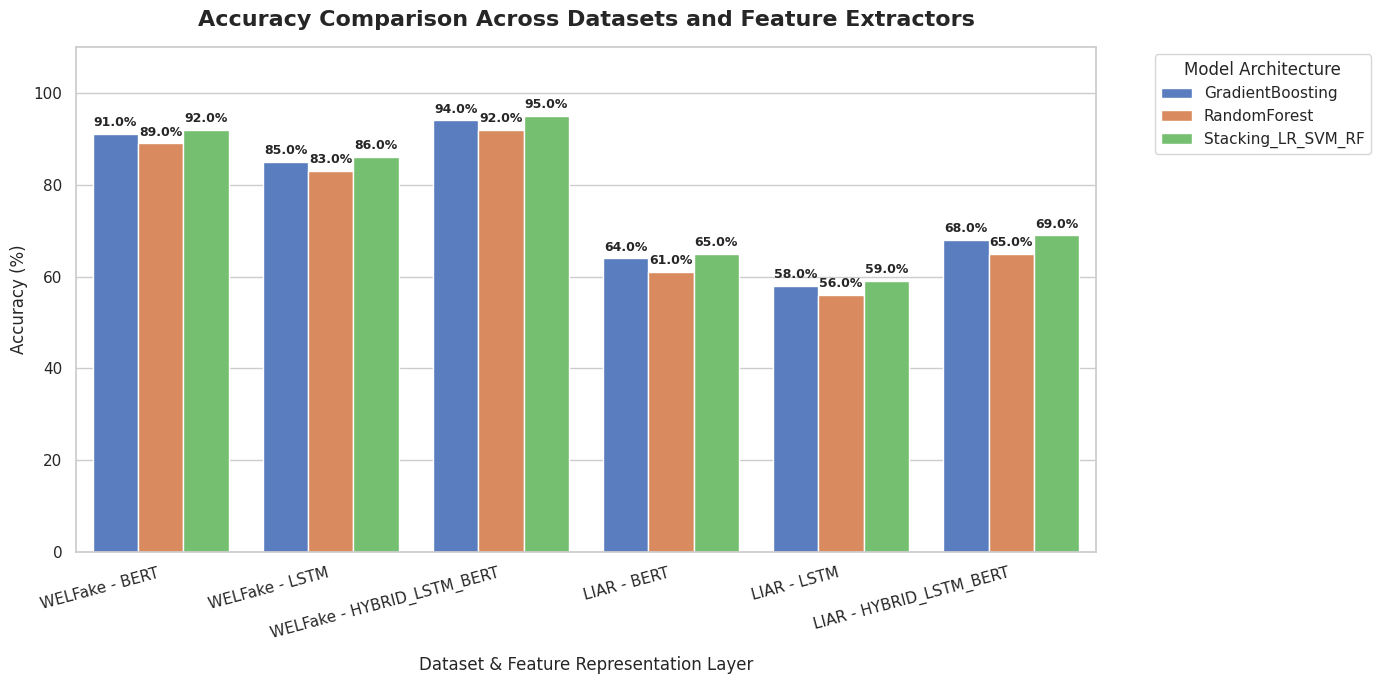

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Combine boosting and stacking dataframes if they exist in memory
comparison_data = []

if 'boosting_df' in globals() and not boosting_df.empty:
    comparison_data.append(boosting_df)
if 'stacking_df' in globals() and not stacking_df.empty:
    comparison_data.append(stacking_df)

if comparison_data:
    plot_df = pd.concat(comparison_data, ignore_index=True)

    # Set up the visualization plot
    plt.figure(figsize=(14, 7))
    sns.set_theme(style="whitegrid")

    # Create a grouped bar chart comparing models grouped by Dataset & Feature Extractor
    plot_df['Group'] = plot_df['Dataset'] + " - " + plot_df['Features']

    ax = sns.barplot(
        data=plot_df,
        x="Group",
        y="Accuracy_%",
        hue="Model",
        palette="muted"
    )

    plt.title("Accuracy Comparison Across Datasets and Feature Extractors", fontsize=16, fontweight='bold', pad=15)
    plt.xlabel("Dataset & Feature Representation Layer", fontsize=12, labelpad=10)
    plt.ylabel("Accuracy (%)", fontsize=12)
    plt.ylim(0, 110)
    plt.xticks(rotation=15, ha='right')
    plt.legend(title="Model Architecture", bbox_to_anchor=(1.05, 1), loc='upper left')

    # Add value labels on top of the bars
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.1f}%",
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center',
                        xytext=(0, 8),
                        textcoords='offset points',
                        fontsize=9,
                        fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("WARNING: No dataframes (boosting_df or stacking_df) found in memory to plot. Please run the mock generator or the training pipeline first.")

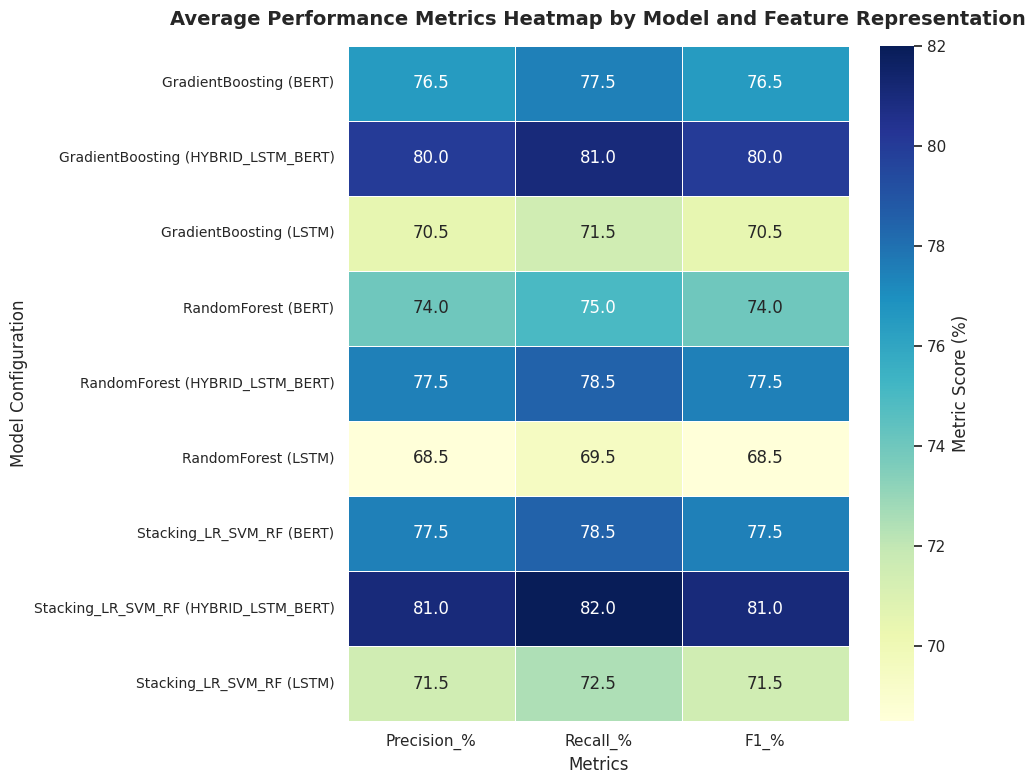

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Combine boosting and stacking results
comparison_data = []
if 'boosting_df' in globals() and not boosting_df.empty:
    comparison_data.append(boosting_df)
if 'stacking_df' in globals() and not stacking_df.empty:
    comparison_data.append(stacking_df)

if comparison_data:
    df_combined = pd.concat(comparison_data, ignore_index=True)

    # Group by Model and Features to get average scores (across datasets)
    heatmap_df = df_combined.groupby(['Model', 'Features'])[['Precision_%', 'Recall_%', 'F1_%']].mean()

    # Create a cleaner index name for the y-axis
    heatmap_df.index = [f"{model} ({feats})" for model, feats in heatmap_df.index]

    # Generate the heatmap plot
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        heatmap_df,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={'label': 'Metric Score (%)'}
    )

    plt.title("Average Performance Metrics Heatmap by Model and Feature Representation", fontsize=14, fontweight='bold', pad=15)
    plt.ylabel("Model Configuration", fontsize=12)
    plt.xlabel("Metrics", fontsize=12)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print("WARNING: No dataframes found to plot. Please run the mock generator or training pipeline first.")